# Credit Default Risk — Step 1: Data, Cleaning and Baseline

**Goal:** predict the probability that a loan applicant will default, using Home Credit's application data (~307,000 real loans).

**This notebook:**
1. Loads the data and checks the default rate
2. Fixes known data problems
3. Engineers the ratios lenders actually use
4. Trains a logistic regression baseline and measures it with ROC AUC and Gini

Data: `application_train.csv` from the Kaggle competition *Home Credit Default Risk*.

In [10]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import RocCurveDisplay, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

DATA_PATH = Path("data/application_train.csv")
RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)
RANDOM_STATE = 42

## 1. Load the data

In [11]:
df = pd.read_csv(DATA_PATH)
print(f"Rows: {len(df):,}   Columns: {df.shape[1]}")
print(f"Default rate: {df['TARGET'].mean():.2%}")
print("Check: the official file has 307,511 rows and 122 columns.")
df.head()

Rows: 246,008   Columns: 122
Default rate: 8.03%
Check: the official file has 307,511 rows and 122 columns.


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,428247,0,Cash loans,F,N,N,0,157500.0,634500.0,30523.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
1,140966,0,Cash loans,M,Y,Y,1,90000.0,1223010.0,51948.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,407283,0,Revolving loans,F,N,Y,0,405000.0,540000.0,27000.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,434300,0,Cash loans,F,N,N,0,90000.0,439740.0,18630.0,...,0,0,0,0,0.0,0.0,0.0,0.0,1.0,5.0
4,446788,0,Cash loans,F,N,N,0,67500.0,323388.0,18054.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0


**Why not accuracy?** Only about 8% of applicants default. A model that predicts "nobody defaults" would be 92% accurate and completely useless. So we measure **ROC AUC**: the probability that the model ranks a random defaulter as riskier than a random non-defaulter. Banks usually report **Gini = 2 × AUC − 1**.

## 2. Fix known data problems

In [12]:
# DAYS_EMPLOYED = 365243 is a placeholder (about 1,000 years), mostly for pensioners and unemployed applicants.
# Treat it as missing, but keep a flag because the group itself behaves differently.
anomaly = df["DAYS_EMPLOYED"] == 365243
print(f"Placeholder DAYS_EMPLOYED rows: {anomaly.sum():,} ({anomaly.mean():.1%})")
print(f"Default rate in that group: {df.loc[anomaly, 'TARGET'].mean():.2%} vs {df.loc[~anomaly, 'TARGET'].mean():.2%} otherwise")

df["DAYS_EMPLOYED_ANOM"] = anomaly.astype(int)
df.loc[anomaly, "DAYS_EMPLOYED"] = np.nan

Placeholder DAYS_EMPLOYED rows: 44,250 (18.0%)
Default rate in that group: 5.30% vs 8.63% otherwise


C:\Users\Azryl\AppData\Local\Temp\ipykernel_27256\1677560605.py:7: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["DAYS_EMPLOYED_ANOM"] = anomaly.astype(int)


## 3. Engineer lender-style features

In [20]:
# Ratios capture affordability better than raw amounts.
df = df.copy()
df["CREDIT_INCOME_RATIO"]  = df["AMT_CREDIT"] / df["AMT_INCOME_TOTAL"]
df["ANNUITY_INCOME_RATIO"] = df["AMT_ANNUITY"] / df["AMT_INCOME_TOTAL"]   # share of income going to repayments
df["CREDIT_TERM"]          = df["AMT_ANNUITY"] / df["AMT_CREDIT"]         # higher = shorter loan
df["AGE_YEARS"]            = -df["DAYS_BIRTH"] / 365.25
df["EMPLOYED_YEARS"]       = -df["DAYS_EMPLOYED"] / 365.25
df["EMPLOYED_TO_AGE"]      = df["EMPLOYED_YEARS"] / df["AGE_YEARS"]

df = df.replace([np.inf, -np.inf], np.nan)
df[["CREDIT_INCOME_RATIO", "ANNUITY_INCOME_RATIO", "CREDIT_TERM", "AGE_YEARS", "EMPLOYED_YEARS"]].describe().round(2)

,CREDIT_INCOME_RATIO,ANNUITY_INCOME_RATIO,CREDIT_TERM,AGE_YEARS,EMPLOYED_YEARS
count,246008.00,246000.00,246000.00,246008.00,201758.00
mean,3.96,0.18,0.05,43.89,6.53
std,2.69,0.09,0.02,11.95,6.40
min,0.00,0.00,0.02,20.50,-0.00
25%,2.02,0.11,0.04,33.97,2.10
50%,3.26,0.16,0.05,43.10,4.51
75%,5.17,0.23,0.06,53.88,8.71
max,84.74,1.88,0.12,69.07,49.04


## 4. Train / test split

In [19]:
y = df["TARGET"]
X = df.drop(columns=["TARGET", "SK_ID_CURR"])

# Stratify so both sets keep the same ~8% default rate.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

categorical = X.select_dtypes(include=["object", "string"]).columns.tolist()
numeric = X.select_dtypes(exclude=["object", "string"]).columns.tolist()
print(f"Train: {len(X_train):,}  Test: {len(X_test):,}")
print(f"Numeric features: {len(numeric)}  Categorical features: {len(categorical)}")

Train: 196,806  Test: 49,202
Numeric features: 111  Categorical features: 16


## 5. Baseline: logistic regression

Preprocessing lives inside the pipeline, so medians and categories are learned from the training data only. That avoids leaking test information into the model.

In [15]:
preprocess = ColumnTransformer([
    ("num", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ]), numeric),
    ("cat", Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=50)),
    ]), categorical),
])

baseline = Pipeline([
    ("prep", preprocess),
    ("model", LogisticRegression(C=0.1, max_iter=2000)),
])
baseline.fit(X_train, y_train)

p_test = baseline.predict_proba(X_test)[:, 1]
auc = roc_auc_score(y_test, p_test)
print(f"Test ROC AUC: {auc:.4f}   Gini: {2 * auc - 1:.4f}")

Test ROC AUC: 0.7474   Gini: 0.4948


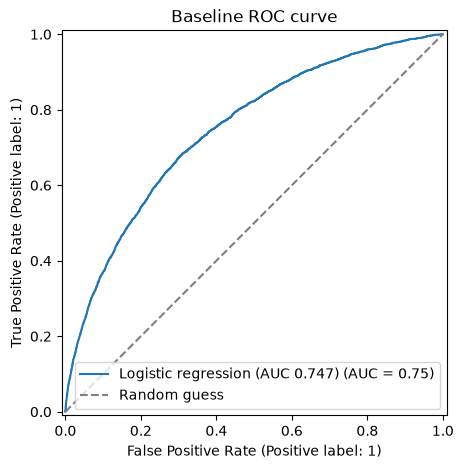

In [16]:
fig, ax = plt.subplots(figsize=(5, 5))
RocCurveDisplay.from_predictions(y_test, p_test, name=f"Logistic regression (AUC {auc:.3f})", ax=ax)
ax.plot([0, 1], [0, 1], "--", color="grey", label="Random guess")
ax.set_title("Baseline ROC curve")
ax.legend(loc="lower right")
fig.savefig(RESULTS / "baseline_roc.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. What drives the baseline?

In [17]:
names = baseline.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(baseline.named_steps["model"].coef_[0], index=names)
top = coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(15)
print("Positive = raises default risk, negative = lowers it (features are standardised)\n")
print(top.round(3).to_string())

Positive = raises default risk, negative = lowers it (features are standardised)

num__AMT_GOODS_PRICE                         -0.970
num__AMT_CREDIT                               0.772
cat__ORGANIZATION_TYPE_Transport: type 3      0.478
num__EXT_SOURCE_3                            -0.464
cat__CODE_GENDER_F                           -0.429
cat__FLAG_OWN_CAR_Y                          -0.387
num__EXT_SOURCE_2                            -0.381
cat__ORGANIZATION_TYPE_Military              -0.353
cat__NAME_HOUSING_TYPE_Office apartment      -0.299
cat__ORGANIZATION_TYPE_Security Ministries   -0.297
cat__NAME_CONTRACT_TYPE_Revolving loans      -0.283
cat__FLAG_OWN_REALTY_N                       -0.277
cat__ORGANIZATION_TYPE_Bank                  -0.272
cat__ORGANIZATION_TYPE_Construction           0.270
cat__EMERGENCYSTATE_MODE_No                  -0.264


In [18]:
metrics = {"model": "logistic_regression", "test_auc": round(auc, 4), "test_gini": round(2 * auc - 1, 4),
           "n_train": len(X_train), "n_test": len(X_test), "default_rate": round(float(y.mean()), 4)}
(RESULTS / "baseline_metrics.json").write_text(json.dumps(metrics, indent=2))
metrics

{'model': 'logistic_regression',
 'test_auc': 0.7474,
 'test_gini': 0.4948,
 'n_train': 196806,
 'n_test': 49202,
 'default_rate': 0.0803}

## Next step
Send back the **Test ROC AUC** and the **top features list**. Step 2 trains XGBoost, compares it to this baseline, calibrates the probabilities and picks an approval threshold based on what a missed default costs the lender.